In [112]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import math
import torch.nn.functional as F
from torch.utils.data import Subset
import numpy as np
import pandas as pd
import copy
from torch.utils.data import ConcatDataset

In [114]:
img_size = 28

transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

batch_size = 128
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)

def make_split_eight_loader(dataset):
    eight_data = [dataset.data[i] for i in range(len(dataset.targets)) if dataset.targets[i] in [8]]
    not_eight_data = [dataset.data[i] for i in range(len(dataset.targets)) if dataset.targets[i] not in [8]]
    
    x = torch.tensor(np.array(eight_data[:len(eight_data)] + not_eight_data[:len(eight_data)]))
    y = torch.tensor([1] * len(eight_data) + [0] * len(eight_data))
    
    perm = torch.randperm(len(x))
    
    dataset.data = x[perm]
    dataset.targets = y[perm]
    return dataset
    return DataLoader(dataset, batch_size=batch_size, shuffle=True)

train_loader = DataLoader(make_split_eight_loader(train_dataset), batch_size=batch_size, shuffle=True)
test_loader = DataLoader(make_split_eight_loader(test_dataset), batch_size=batch_size, shuffle=False)

In [115]:
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class BinaryClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=3, padding=1),
            nn.GroupNorm(32, 64), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.GroupNorm(32, 128), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.GroupNorm(32, 256), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.GroupNorm(32, 512), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten()
        )
        
        self.time_mlp = nn.Sequential(
            nn.Linear(1, 128),
            nn.ReLU(),
            nn.Linear(128, 128)
        )
        
        self.fc = nn.Linear(512 + 128, 2)

    def forward(self, x, t):
        img_feats = self.features(x)
        
        if t.dim() == 1:
            t = t.unsqueeze(-1).float()
            
        time_feats = self.time_mlp(t)
        
        combined = torch.cat([img_feats, time_feats], dim=1)
        return self.fc(combined)

model = BinaryClassifier().to(device)

total_params = sum(p.numel() for p in model.parameters())
print(f"Total Parameters: {total_params:,}") 
    
with torch.no_grad():
    img = torch.randn(1, 1, 28, 28).to(device)
    t = torch.tensor([500]).to(device)
    output = model(img, t)
    print(f"Output with time: {output}")

Total Parameters: 1,569,794
Output with time: tensor([[ 3.9847, 23.5538]], device='cuda:0')


In [116]:
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import argparse
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

pre_epoch = 0
BATCH_SIZE = 128
LR = 0.001
# Set the number of epochs
EPOCH = 50
pre_epoch = 0
n_steps = 1000
classes = (0, 1)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

beta = torch.linspace(0.0001, 0.02, n_steps).to(device)
alpha = 1 - beta
alpha_bar = torch.cumprod(alpha, dim=0)

In [61]:
from tqdm.notebook import tqdm

for epoch in range(pre_epoch, EPOCH):
    model.train()
    sum_loss = 0.0
    correct = 0.0
    total = 0.0
    
    pbar = tqdm(enumerate(train_loader), total=len(train_loader), desc=f"Epoch {epoch + 1}/{EPOCH}")
    
    for i, data in pbar:
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)


        B = inputs.size(0)
        
        t = torch.randint(0, 500, (B,), device="cuda").long()
        noise = torch.randn_like(inputs)
        alpha_bar_t = alpha_bar[t].view(-1, 1, 1, 1)
        inputs = torch.sqrt(alpha_bar_t) * inputs + torch.sqrt(1 - alpha_bar_t) * noise

        optimizer.zero_grad()
        outputs = model(inputs, t)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        sum_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += predicted.eq(labels.data).cpu().sum()
        
        pbar.set_postfix({
            'Loss': f"{sum_loss / (i + 1):.3f}",
            'Acc': f"{100. * correct / total:.2f}%"
        })
        
    model.eval()
    test_correct = 0
    test_total = 0
    with torch.no_grad():
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            
            B = images.size(0)
            t = torch.randint(0, 500, (B,), device="cuda").long()
            noise = torch.randn_like(images)
            alpha_bar_t = alpha_bar[t].view(-1, 1, 1, 1)
            images = torch.sqrt(alpha_bar_t) * images + torch.sqrt(1 - alpha_bar_t) * noise
            
            outputs = model(images, t)
            _, predicted = torch.max(outputs.data, 1)
            test_total += labels.size(0)
            test_correct += (predicted == labels).sum()
            
    print(f"--- Epoch {epoch + 1} Finished | Test Acc: {100. * test_correct / test_total:.3f}% ---")

print(f'Train has finished, total epoch is {EPOCH}')

Epoch 1/50:   0%|          | 0/92 [00:00<?, ?it/s]

--- Epoch 1 Finished | Test Acc: 83.678% ---


Epoch 2/50:   0%|          | 0/92 [00:00<?, ?it/s]

--- Epoch 2 Finished | Test Acc: 89.703% ---


Epoch 3/50:   0%|          | 0/92 [00:00<?, ?it/s]

--- Epoch 3 Finished | Test Acc: 92.061% ---


... (90 outputs left out)

Epoch 49/50:   0%|          | 0/92 [00:00<?, ?it/s]

--- Epoch 49 Finished | Test Acc: 95.966% ---


Epoch 50/50:   0%|          | 0/92 [00:00<?, ?it/s]

--- Epoch 50 Finished | Test Acc: 96.112% ---
Train has finished, total epoch is 50


In [111]:
# torch.save(model.state_dict(), "8_binary_clsf.pth")

In [134]:
model = BinaryClassifier().to(device)
model.load_state_dict(torch.load("8_binary_clsf.pth", map_location=device))

<All keys matched successfully>

Top 10 most indecisive images found (closest to 50/50):
Rank 1 | dist_from_0.5: 0.024572
Probabilities: [0.52457166 0.4754283 ]


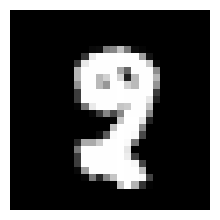

Rank 2 | dist_from_0.5: 0.047805
Probabilities: [0.5478054  0.45219457]


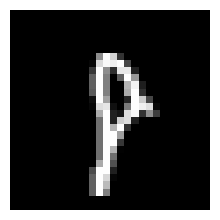

Rank 3 | dist_from_0.5: 0.061124
Probabilities: [0.43887576 0.56112427]


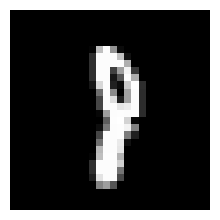

Rank 4 | dist_from_0.5: 0.071679
Probabilities: [0.42832056 0.5716794 ]


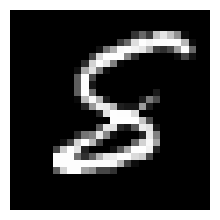

Rank 5 | dist_from_0.5: 0.071730
Probabilities: [0.42826962 0.5717304 ]


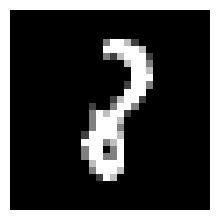

Rank 6 | dist_from_0.5: 0.083946
Probabilities: [0.41605437 0.58394563]


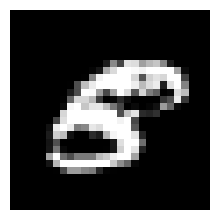

Rank 7 | dist_from_0.5: 0.094737
Probabilities: [0.40526268 0.5947373 ]


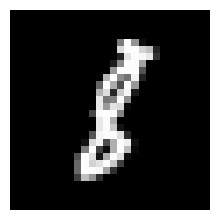

Rank 8 | dist_from_0.5: 0.109977
Probabilities: [0.39002344 0.6099766 ]


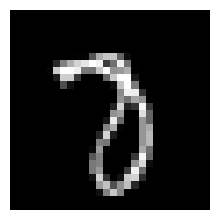

Rank 9 | dist_from_0.5: 0.111769
Probabilities: [0.38823113 0.6117689 ]


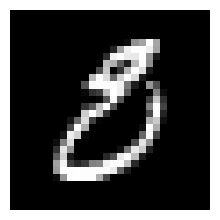

Rank 10 | dist_from_0.5: 0.157592
Probabilities: [0.34240788 0.6575921 ]


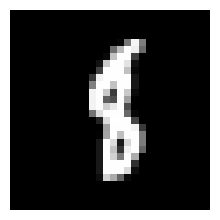

In [177]:
import torch
import numpy as np
import random
import matplotlib.pyplot as plt

# --- Setup Seeds ---
SEED = 4
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(False)

model.eval()

most_indecisive = [] 

with torch.no_grad():
    for data in test_loader:
        images, labels = data
        images = images.to(device)
        
        B = images.size(0)
        t = torch.randint(0, 500, (B,), device=device).long()
        
        outputs = model(images, t)

        probs = torch.softmax(outputs, dim=1)

        scores = (probs[:, 0] - 0.5).abs()
        
        for i in range(B):
            score_val = scores[i].item()
            
            if len(most_indecisive) < 10 or score_val < most_indecisive[-1]['score']:
                
                candidate = {
                    'score': score_val,
                    'image': images[i].cpu(),
                    'probs': probs[i].cpu()
                }
                
                most_indecisive.append(candidate)
                
                most_indecisive.sort(key=lambda x: x['score'])
                most_indecisive = most_indecisive[:10]

print(f"Top {len(most_indecisive)} most indecisive images found (closest to 50/50):")

for rank, item in enumerate(most_indecisive):

    print(f"Rank {rank + 1} | dist_from_0.5: {item['score']:.6f}")
    print(f"Probabilities: {item['probs'].numpy()}") 
    
    fig = plt.figure(frameon=False, figsize=(2, 2))
    ax = plt.Axes(fig, [0., 0., 1., 1.])
    ax.set_axis_off()
    fig.add_axes(ax)
    
    ax.imshow(item['image'][0], cmap="gray")
    plt.show()